Language: **English (default)** | [Polski](examples.ipynb)

# Lecture 07. Transfer learning on ResNet18

This companion to [`lecture.en.md`](lecture.en.md) uses 10 balanced
Caltech101 classes with good ImageNet coverage. It compares training from
scratch, two frozen-backbone variants, and partial fine-tuning.

In [1]:
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision.datasets as tvd
from PIL import Image
from torchvision.models import ResNet18_Weights, resnet18

torch.manual_seed(0)
torch.set_num_threads(4)  # BLAS thread stability under jupyter/ipykernel
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


## 1. Data. A 10-class Caltech101 subset

The 10 selected classes have good ImageNet coverage: `airplanes, Motorbikes,
elephant, kangaroo, grand_piano, car_side, dalmatian, butterfly, starfish,
dolphin`. Each class contains 60 images, split 36/12/12 across training,
validation, and test sets.

In [2]:
import contextlib
import io

_REPO_ROOT = next(
    (
        parent
        for parent in (Path.cwd(), *Path.cwd().parents)
        if (parent / "pyproject.toml").is_file()
    ),
    Path.cwd(),
)
DATA_CACHE_DIR = (
    Path(os.environ.get("DEEP_LEARNING_DATA_CACHE", _REPO_ROOT / "data_cache"))
    .expanduser()
    .resolve()
)

CLASSES = [
    "airplanes",
    "Motorbikes",
    "elephant",
    "kangaroo",
    "grand_piano",
    "car_side",
    "dalmatian",
    "butterfly",
    "starfish",
    "dolphin",
]
PER_CLASS = 60

weights = ResNet18_Weights.IMAGENET1K_V1
preprocess = weights.transforms()
print("Preprocessing required by the pretrained weights:")
print(preprocess)

# Downloading prints progress (a tqdm bar, by default on stderr) every few
# percent -- in a notebook that is just noise, so we silence both streams
# here (the file and its MD5 are verified by torchvision regardless of
# what it prints to the screen).
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    full_ds = tvd.Caltech101(root=DATA_CACHE_DIR, download=True, target_type="category")
    resnet18(weights=weights)  # pre-download the weights into the local cache (quietly)
class_to_label = {c: i for i, c in enumerate(CLASSES)}


def load_image(ds, idx):
    # Caltech101.__getitem__ unconditionally imports scipy (even for
    # target_type="category", which never needs it) -- we read the JPEG
    # directly following the dataset's own path convention, instead of
    # adding scipy as a dependency for an annotation function we never use.
    path = os.path.join(
        ds.root,
        "101_ObjectCategories",
        ds.categories[ds.y[idx]],
        f"image_{ds.index[idx]:04d}.jpg",
    )
    return Image.open(path).convert("RGB")


selected_indices, selected_labels = [], []
counts = {c: 0 for c in CLASSES}
for idx, y in enumerate(full_ds.y):
    cat_name = full_ds.categories[y]
    if cat_name in class_to_label and counts[cat_name] < PER_CLASS:
        selected_indices.append(idx)
        selected_labels.append(class_to_label[cat_name])
        counts[cat_name] += 1

print("\nnumber of images per class:", counts)
assert all(v == PER_CLASS for v in counts.values()), "the set is not balanced"

Preprocessing required by the pretrained weights:
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

number of images per class: {'airplanes': 60, 'Motorbikes': 60, 'elephant': 60, 'kangaroo': 60, 'grand_piano': 60, 'car_side': 60, 'dalmatian': 60, 'butterfly': 60, 'starfish': 60, 'dolphin': 60}


X=(600, 3, 224, 224)  y=(600,)


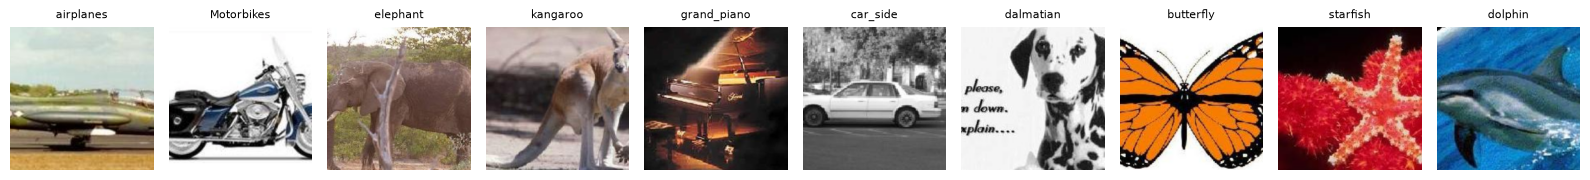

In [3]:
imgs = [preprocess(load_image(full_ds, idx)) for idx in selected_indices]
X = torch.stack(imgs)
y = torch.tensor(selected_labels)
print(f"X={tuple(X.shape)}  y={tuple(y.shape)}")

fig, axes = plt.subplots(1, 10, figsize=(16, 2))
unnorm_mean = torch.tensor(preprocess.mean).view(3, 1, 1)
unnorm_std = torch.tensor(preprocess.std).view(3, 1, 1)
for c, ax in enumerate(axes):
    first_idx = (y == c).nonzero()[0].item()
    img_show = (X[first_idx] * unnorm_std + unnorm_mean).clamp(0, 1)
    ax.imshow(img_show.permute(1, 2, 0))
    ax.set_title(CLASSES[c], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
g = torch.Generator().manual_seed(0)
train_idx, val_idx, test_idx = [], [], []
for c in range(10):
    class_positions = (y == c).nonzero().flatten()
    perm = class_positions[torch.randperm(len(class_positions), generator=g)]
    train_idx.append(perm[:36])
    val_idx.append(perm[36:48])
    test_idx.append(perm[48:60])
train_idx, val_idx, test_idx = torch.cat(train_idx), torch.cat(val_idx), torch.cat(test_idx)
assert len(set(train_idx.tolist()) & set(val_idx.tolist()) & set(test_idx.tolist())) == 0

X_train, y_train = X[train_idx].to(device), y[train_idx].to(device)
X_val, y_val = X[val_idx].to(device), y[val_idx].to(device)
X_test, y_test = X[test_idx].to(device), y[test_idx].to(device)
print(f"train={tuple(X_train.shape)}  val={tuple(X_val.shape)}  test={tuple(X_test.shape)}")


def stratified_train_subset(n_per_class):
    """X_train/y_train are 10 consecutive blocks of 36 (classes 0..9) -- a
    plain prefix X_train[:n] would take images only from the first ~n/36
    classes. This function takes the first n_per_class images FROM EACH
    class."""
    idx = torch.cat([torch.arange(c * 36, c * 36 + n_per_class) for c in range(10)])
    return idx

train=(360, 3, 224, 224)  val=(120, 3, 224, 224)  test=(120, 3, 224, 224)


## 2. How many parameters are actually trained

The head is replaced with a 10-class version. Parameter behavior is checked
not only through `requires_grad`, but also through a real optimizer step and
a comparison of weights before and after the update.

In [5]:
def build_model(pretrained, n_classes=10):
    w = ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    model = resnet18(weights=w)
    model.fc = nn.Linear(model.fc.in_features, n_classes)
    return model.to(device)


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


def freeze_all_but(model, submodules):
    for p in model.parameters():
        p.requires_grad = False
    for m in submodules:
        for p in m.parameters():
            p.requires_grad = True


m_check = build_model(pretrained=True)
freeze_all_but(m_check, [m_check.fc])

before = {n: p.detach().clone() for n, p in m_check.named_parameters()}
opt = torch.optim.Adam([p for p in m_check.parameters() if p.requires_grad], lr=0.01)
loss_fn = nn.CrossEntropyLoss()
m_check.eval()  # frozen backbone: eval(), so BatchNorm does not change either (section 3 below)
for _ in range(3):
    opt.zero_grad()
    loss = loss_fn(m_check(X_train[:8]), y_train[:8])
    loss.backward()
    opt.step()

changed_trainable, unchanged_trainable, changed_frozen = [], [], []
for n, p in m_check.named_parameters():
    same = torch.equal(before[n], p.detach())
    if p.requires_grad:
        (unchanged_trainable if same else changed_trainable).append(n)
    elif not same:
        changed_frozen.append(n)

total, trainable = count_params(m_check)
print(f"Frozen backbone: {trainable:,} / {total:,} trainable ({100 * trainable / total:.2f}%)")
print(f"  trainable tensors that ACTUALLY changed: {len(changed_trainable)}")
print(f"  trainable tensors with no change (suspicious, should = 0): {len(unchanged_trainable)}")
print(f"  frozen tensors that changed anyway (BUG, should = 0): {len(changed_frozen)}")
assert len(unchanged_trainable) == 0 and len(changed_frozen) == 0

Frozen backbone: 5,130 / 11,181,642 trainable (0.05%)
  trainable tensors that ACTUALLY changed: 2
  trainable tensors with no change (suspicious, should = 0): 0
  frozen tensors that changed anyway (BUG, should = 0): 0


In [6]:
# analogous verification for partial and full fine-tuning
for name, submods_fn in [
    ("Partial fine-tuning (layer4 + fc)", lambda m: [m.layer4, m.fc]),
    ("Full fine-tuning", lambda m: [m]),
]:
    m = build_model(pretrained=True)
    freeze_all_but(m, submods_fn(m))
    before = {n: p.detach().clone() for n, p in m.named_parameters()}
    opt = torch.optim.Adam([p for p in m.parameters() if p.requires_grad], lr=0.0001)
    m.train()
    for _ in range(3):
        opt.zero_grad()
        loss = loss_fn(m(X_train[:8]), y_train[:8])
        loss.backward()
        opt.step()
    changed_frozen = [
        n
        for n, p in m.named_parameters()
        if not p.requires_grad and not torch.equal(before[n], p.detach())
    ]
    total, trainable = count_params(m)
    print(
        f"{name}: {trainable:,} / {total:,} trainable ({100 * trainable / total:.2f}%), "
        f"frozen-but-changed: {len(changed_frozen)} (should = 0)"
    )
    assert len(changed_frozen) == 0

Partial fine-tuning (layer4 + fc): 8,398,858 / 11,181,642 trainable (75.11%), frozen-but-changed: 0 (should = 0)


Full fine-tuning: 11,181,642 / 11,181,642 trainable (100.00%), frozen-but-changed: 0 (should = 0)


## 3. BatchNorm, `requires_grad=False`, and `model.eval()`

ResNet18 has 20 `BatchNorm2d` layers. The experiment checks whether their
`running_mean` changes during frozen-backbone training in each model mode.

In [7]:
def bn_drift_check(train_mode):
    m = build_model(pretrained=True)
    freeze_all_but(m, [m.fc])
    before_bn = {n: b.detach().clone() for n, b in m.named_buffers() if "running_mean" in n}

    opt = torch.optim.Adam(m.fc.parameters(), lr=0.01)
    m.train() if train_mode else m.eval()
    for _ in range(3):
        opt.zero_grad()
        loss = loss_fn(m(X_train[:8]), y_train[:8])
        loss.backward()
        opt.step()

    n_changed = sum(
        1
        for n, b in m.named_buffers()
        if "running_mean" in n and not torch.equal(before_bn[n], b.detach())
    )
    return n_changed


n_bn = len([n for n, _ in build_model(pretrained=True).named_buffers() if "running_mean" in n])
changed_train = bn_drift_check(train_mode=True)
changed_eval = bn_drift_check(train_mode=False)
print(f"Number of BatchNorm layers in ResNet18: {n_bn}")
print(
    f"model.train(), backbone frozen via requires_grad=False: "
    f"{changed_train}/{n_bn} BN layers updated running_mean"
)
print(
    f"model.eval(),  backbone frozen via requires_grad=False: "
    f"{changed_eval}/{n_bn} BN layers updated running_mean"
)
assert changed_train == n_bn, "expected ALL BN layers to drift in train()"
assert changed_eval == 0, "eval() should fully stop running-stat updates"

Number of BatchNorm layers in ResNet18: 20
model.train(), backbone frozen via requires_grad=False: 20/20 BN layers updated running_mean
model.eval(),  backbone frozen via requires_grad=False: 0/20 BN layers updated running_mean


## 4. Comparative experiment

Four approaches solve the same task. Each reports parameters, loss,
validation accuracy, and measured training and inference time.

In [8]:
def train_eval(model, epochs, param_groups=None, lr=0.001, batch_size=16, seed=0):
    torch.manual_seed(seed)
    if param_groups is None:
        param_groups = [p for p in model.parameters() if p.requires_grad]
        opt = torch.optim.Adam(param_groups, lr=lr)
    else:
        opt = torch.optim.Adam(param_groups)
    n = X_train.shape[0]

    start = time.time()
    for _ in range(epochs):
        perm = torch.randperm(n)
        for i in range(0, n, batch_size):
            idx = perm[i : i + batch_size]
            opt.zero_grad()
            loss = loss_fn(model(X_train[idx]), y_train[idx])
            loss.backward()
            opt.step()
    train_time = time.time() - start

    model.eval()
    with torch.no_grad():
        val_acc = (model(X_val).argmax(1) == y_val).float().mean().item()
        start = time.time()
        test_logits = model(X_test)
        infer_time_ms = (time.time() - start) / X_test.shape[0] * 1000
    test_acc = (test_logits.argmax(1) == y_test).float().mean().item()
    return {
        "val_acc": val_acc,
        "test_acc": test_acc,
        "train_time_s": train_time,
        "infer_time_ms_per_img": infer_time_ms,
    }


results = {}

### 4.1 Training from scratch (random initialization)

In [9]:
m_scratch = build_model(pretrained=False)
total, trainable = count_params(m_scratch)
res = train_eval(m_scratch, epochs=8)
res["total_params"], res["trainable_params"] = total, trainable
results["from scratch"] = res
print(f"training from scratch: params={trainable:,}/{total:,} (100%)")
print(res)

training from scratch: params=11,181,642/11,181,642 (100%)
{'val_acc': 0.6499999761581421, 'test_acc': 0.5416666865348816, 'train_time_s': 84.85613512992859, 'infer_time_ms_per_img': 11.218740542729696, 'total_params': 11181642, 'trainable_params': 11181642}


### 4.2 Frozen backbone, naive execution and feature caching

The naive variant runs a full backbone forward pass in every epoch despite
unchanged weights. The cached variant extracts features once in
`inference_mode()` and `eval()`, then trains the head on saved 512-dimensional
vectors.

In [10]:
m_frozen_naive = build_model(pretrained=True)
freeze_all_but(m_frozen_naive, [m_frozen_naive.fc])
m_frozen_naive.eval()
total, trainable = count_params(m_frozen_naive)
res_naive = train_eval(m_frozen_naive, epochs=5)
print(
    f"Frozen backbone (naive, 5 epochs): time={res_naive['train_time_s']:.1f}s  "
    f"val_acc={res_naive['val_acc']:.3f}"
)

Frozen backbone (naive, 5 epochs): time=25.2s  val_acc=1.000


In [11]:
m_frozen_cached = build_model(pretrained=True)
m_frozen_cached.eval()
feat_extractor = nn.Sequential(*list(m_frozen_cached.children())[:-1])  # without fc

start = time.time()
with torch.inference_mode():
    feat_train = feat_extractor(X_train).flatten(1)
    feat_val = feat_extractor(X_val).flatten(1)
    feat_test = feat_extractor(X_test).flatten(1)
extract_time = time.time() - start
print(
    f"one-off feature extraction (whole dataset): {extract_time:.2f}s, "
    f"feature shape: {tuple(feat_train.shape)}"
)


def train_eval_head(epochs, n_per_class=None, seed=0):
    torch.manual_seed(seed)
    if n_per_class is None:
        ft, yt = feat_train, y_train
    else:
        sub_idx = stratified_train_subset(n_per_class)
        ft, yt = feat_train[sub_idx], y_train[sub_idx]
    head = nn.Linear(512, 10).to(device)
    opt = torch.optim.Adam(head.parameters(), lr=0.001)
    start = time.time()
    for _ in range(epochs):
        perm = torch.randperm(ft.shape[0])
        for i in range(0, ft.shape[0], 16):
            idx = perm[i : i + 16]
            opt.zero_grad()
            loss = loss_fn(head(ft[idx]), yt[idx])
            loss.backward()
            opt.step()
    head_time = time.time() - start
    head.eval()
    with torch.no_grad():
        val_acc = (head(feat_val).argmax(1) == y_val).float().mean().item()
        test_acc = (head(feat_test).argmax(1) == y_test).float().mean().item()
    return head, head_time, val_acc, test_acc


_, head_time_5ep, val_acc_5ep, _ = train_eval_head(epochs=5)
print("\nComparison at the SAME number of epochs (5):")
print(f"  naive:          {res_naive['train_time_s']:.1f}s   val_acc={res_naive['val_acc']:.3f}")
print(
    f"  with cache:     {extract_time + head_time_5ep:.2f}s   val_acc={val_acc_5ep:.3f}  "
    f"(extraction {extract_time:.1f}s + head {head_time_5ep:.3f}s)"
)
print(f"  speedup:        {res_naive['train_time_s'] / (extract_time + head_time_5ep):.1f}x")

one-off feature extraction (whole dataset): 7.15s, feature shape: (360, 512)

Comparison at the SAME number of epochs (5):
  naive:          25.2s   val_acc=1.000
  with cache:     7.17s   val_acc=1.000  (extraction 7.1s + head 0.022s)
  speedup:        3.5x


In [12]:
# "final" variant: since training the head on the cache is nearly free,
# we can afford more epochs with no extra extraction cost
head_final, head_time_final, val_acc_final, test_acc_final = train_eval_head(epochs=15)
results["frozen backbone (cache)"] = {
    "total_params": total,
    "trainable_params": 512 * 10 + 10,
    "val_acc": val_acc_final,
    "test_acc": test_acc_final,
    "train_time_s": extract_time + head_time_final,
    "infer_time_ms_per_img": res_naive["infer_time_ms_per_img"],
}
print(
    f"Frozen backbone, final version (15 epochs on cache): "
    f"val_acc={val_acc_final:.3f} test_acc={test_acc_final:.3f} "
    f"time={extract_time + head_time_final:.2f}s"
)

Frozen backbone, final version (15 epochs on cache): val_acc=1.000 test_acc=0.983 time=7.21s


**Cache validity.** Saved features remain correct only with a completely
frozen backbone and deterministic preprocessing. Fine-tuning changes the
features after the first optimizer step, which makes the cache stale. The
cache does not replace fine-tuning. It only accelerates head training over
a genuinely unchanged backbone.

### 4.3 Partial fine-tuning (`layer4` + `fc`, two learning rates)

In [13]:
m_partial = build_model(pretrained=True)
freeze_all_but(m_partial, [m_partial.layer4, m_partial.fc])
m_partial.train()
total, trainable = count_params(m_partial)
param_groups = [
    {"params": m_partial.layer4.parameters(), "lr": 0.0001},  # eta_backbone: small steps
    {"params": m_partial.fc.parameters(), "lr": 0.001},  # eta_head: larger steps
]
res_partial = train_eval(m_partial, epochs=8, param_groups=param_groups)
res_partial["total_params"], res_partial["trainable_params"] = total, trainable
results["partial fine-tuning"] = res_partial
print(f"partial fine-tuning: params={trainable:,}/{total:,} ({100 * trainable / total:.1f}%)")
print(res_partial)

partial fine-tuning: params=8,398,858/11,181,642 (75.1%)
{'val_acc': 1.0, 'test_acc': 0.9750000238418579, 'train_time_s': 48.724212884902954, 'infer_time_ms_per_img': 11.168217658996582, 'total_params': 11181642, 'trainable_params': 8398858}


### 4.4 Multiple seeds for the more expensive strategies

Expensive training from scratch runs once. The cached frozen backbone and
partial fine-tuning are repeated for two seeds to assess stability across
runs.

In [14]:
for seed in [0, 1]:
    _, _, val_acc_s, test_acc_s = train_eval_head(epochs=15, seed=seed)
    print(f"[cache]   seed={seed}: val_acc={val_acc_s:.3f} test_acc={test_acc_s:.3f}")

for seed in [0, 1]:
    m = build_model(pretrained=True)
    freeze_all_but(m, [m.layer4, m.fc])
    m.train()
    pg = [
        {"params": m.layer4.parameters(), "lr": 0.0001},
        {"params": m.fc.parameters(), "lr": 0.001},
    ]
    r = train_eval(m, epochs=8, param_groups=pg, seed=seed)
    print(f"[partial] seed={seed}: val_acc={r['val_acc']:.3f} test_acc={r['test_acc']:.3f}")

[cache]   seed=0: val_acc=1.000 test_acc=0.983
[cache]   seed=1: val_acc=1.000 test_acc=1.000


[partial] seed=0: val_acc=1.000 test_acc=0.958


[partial] seed=1: val_acc=1.000 test_acc=0.992


### 4.5 Epoch budget and time budget

Epoch count and CPU time describe two different experimental budgets.

In [15]:
print(
    f"{'strategy':30s} {'trainable params':>18s} {'%':>7s} {'val_acc':>8s} "
    f"{'train time':>14s} {'inference/image':>18s}"
)
for name, r in results.items():
    pct = 100 * r["trainable_params"] / r["total_params"]
    print(
        f"{name:30s} {r['trainable_params']:>18,} {pct:>6.2f}% {r['val_acc']:>8.3f} "
        f"{r['train_time_s']:>12.1f}s {r['infer_time_ms_per_img']:>16.2f}ms"
    )

strategy                         trainable params       %  val_acc     train time    inference/image
from scratch                           11,181,642 100.00%    0.650         84.9s            11.22ms
frozen backbone (cache)                     5,130   0.05%    1.000          7.2s            11.05ms
partial fine-tuning                     8,398,858  75.11%    1.000         48.7s            11.17ms


## 5. Effect of training set size

Training from scratch is compared with a frozen backbone at 6, 18, and 36
images per class, or 10%, 50%, and 100% of the training data. The subsample
remains balanced. A plain `X_train` and `y_train` prefix would mostly contain
the first classes because the data forms 10 consecutive blocks of 36 images.

In [16]:
import gc

sweep_sizes_per_class = [6, 18, 36]
sweep_results = {"from scratch": [], "frozen (cache)": []}

for k in sweep_sizes_per_class:
    _, _, val_acc_cache, _ = train_eval_head(epochs=15, n_per_class=k)
    sweep_results["frozen (cache)"].append(val_acc_cache)
    print(f"n_train={k * 10:>3} ({k}/class)  frozen (cache): val_acc={val_acc_cache:.3f}")

for k in sweep_sizes_per_class:
    sub_idx = stratified_train_subset(k)
    Xs, ys = X_train[sub_idx], y_train[sub_idx]
    m = build_model(pretrained=False)
    torch.manual_seed(0)
    opt = torch.optim.Adam(m.parameters(), lr=0.001)
    n = Xs.shape[0]
    for _ in range(8):
        perm = torch.randperm(n)
        for i in range(0, n, 16):
            idx = perm[i : i + 16]
            opt.zero_grad()
            loss = loss_fn(m(Xs[idx]), ys[idx])
            loss.backward()
            opt.step()
    m.eval()
    with torch.no_grad():
        val_acc_scratch = (m(X_val).argmax(1) == y_val).float().mean().item()
    sweep_results["from scratch"].append(val_acc_scratch)
    print(f"n_train={k * 10:>3} ({k}/class)  from scratch:   val_acc={val_acc_scratch:.3f}")
    del m
    gc.collect()

sweep_sizes = [k * 10 for k in sweep_sizes_per_class]

n_train= 60 (6/class)  frozen (cache): val_acc=0.992
n_train=180 (18/class)  frozen (cache): val_acc=1.000
n_train=360 (36/class)  frozen (cache): val_acc=1.000


n_train= 60 (6/class)  from scratch:   val_acc=0.250


n_train=180 (18/class)  from scratch:   val_acc=0.517


n_train=360 (36/class)  from scratch:   val_acc=0.575


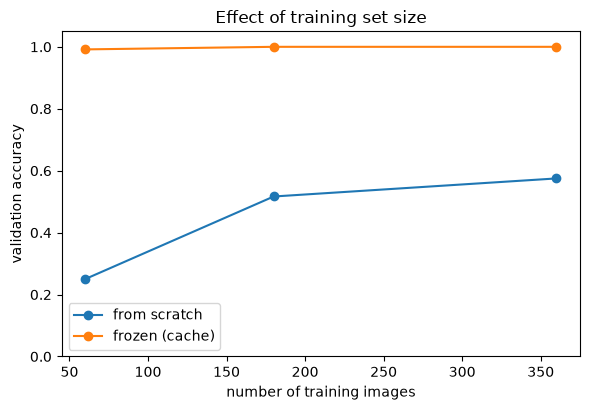

In [17]:
fig, ax = plt.subplots(figsize=(6, 4.2))
for name, accs in sweep_results.items():
    ax.plot(sweep_sizes, accs, marker="o", label=name)
ax.set_xlabel("number of training images")
ax.set_ylabel("validation accuracy")
ax.set_title("Effect of training set size")
ax.legend()
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

## Summary

- A real optimizer step confirms that frozen parameters remain constant and
  trainable parameters are updated.
- `model.train()` still updates every BatchNorm layer in a frozen backbone.
  Stopping the statistics requires `model.eval()`.
- A feature cache greatly accelerates head training but is valid only for
  an unchanged backbone.
- The interpretation in [`lecture.en.md`](lecture.en.md) refers directly to
  the measured accuracy and time values above.